In [1]:
import glob
from Autoencoder.latent_check.latent_dih_analysis import *
import torch, torch.nn as nn

In [14]:
checkpoint = "../../results_real/AE_dihedral_261026/dihedral_ae_n_v1/all_runs_streamed/models/ae_latent4.pt"
dev = torch.device("mps")

In [3]:
class AE(nn.Module):
    def __init__(self, n_in, latent, HIDDEN):
        super().__init__()
        h1, h2 = HIDDEN
        self.enc = nn.Sequential(nn.Linear(n_in, h1), nn.GELU(), nn.Linear(h1, h2), nn.GELU(),
                                 nn.Linear(h2, latent))
        self.dec = nn.Sequential(nn.Linear(latent, h2), nn.GELU(), nn.Linear(h2, h1), nn.GELU(),
                                 nn.Linear(h1, n_in), nn.Tanh())

    def forward(self, x):
        z = self.enc(x)
        return self.dec(z), z

In [7]:
def load_model(cpkt, device='cpu'):
    ck=torch.load(cpkt, map_location=device, weights_only=False)
    model = AE(ck['n_in'], ck['latent'], HIDDEN=tuple(ck['hidden']))
    model.load_state_dict(ck['state_dict'])
    model.eval().to(device)
    return model, list(ck['all_names']), ck
def prepare_input(deg, names, all_names):
    pos = {n: i for i, n in enumerate(all_names)}
    keep = [j for j, n in enumerate(names) if n in pos]
    unknown = [n for n in names if n not in pos]
    if unknown:
        warnings.warn(f"{len(unknown)} column(s) are not known to the model and are dropped: {unknown[:8]}")
    if not keep:
        raise ValueError("none of the columns match the model's all_names")
    idx = [pos[names[j]] for j in keep]
    D = len(all_names)
    full = np.zeros((len(deg), D), np.float32)
    full[:, idx] = np.asarray(deg, np.float32)[:, keep]
    pres = np.zeros(D, bool)
    pres[idx] = True
    m = pres.astype(np.float32)
    r = np.deg2rad(full).astype(np.float32)
    x = np.concatenate([np.cos(r) * m, np.sin(r) * m], axis=1).astype(np.float32)
    x = np.nan_to_num(x, nan=0.0).astype(np.float32)
    mask = np.concatenate([m, m])
    return x, mask, full, pres

In [15]:
model, all_names, ck = load_model(checkpoint, dev)
files = sorted(glob.glob("../../dihedrals/*/bb_dihedrals.txt"))
data = collect_latents(model, all_names, files, prepare_input, stride=50, max_per_run=1000, device=dev)
z = data["z"]; p = pca(z)

latent size 64: 64 dimensions with std > 1% of the largest one
PCA: 25 components for 90% of the variance, 51 for 99%; participation ratio 13.2


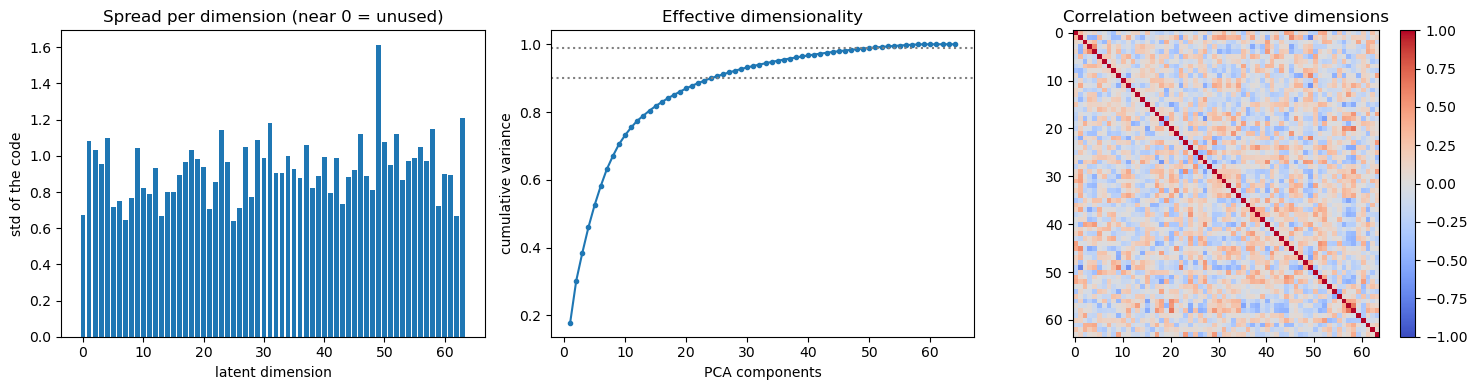

In [10]:
plot_overview(z, p)                                       # 1

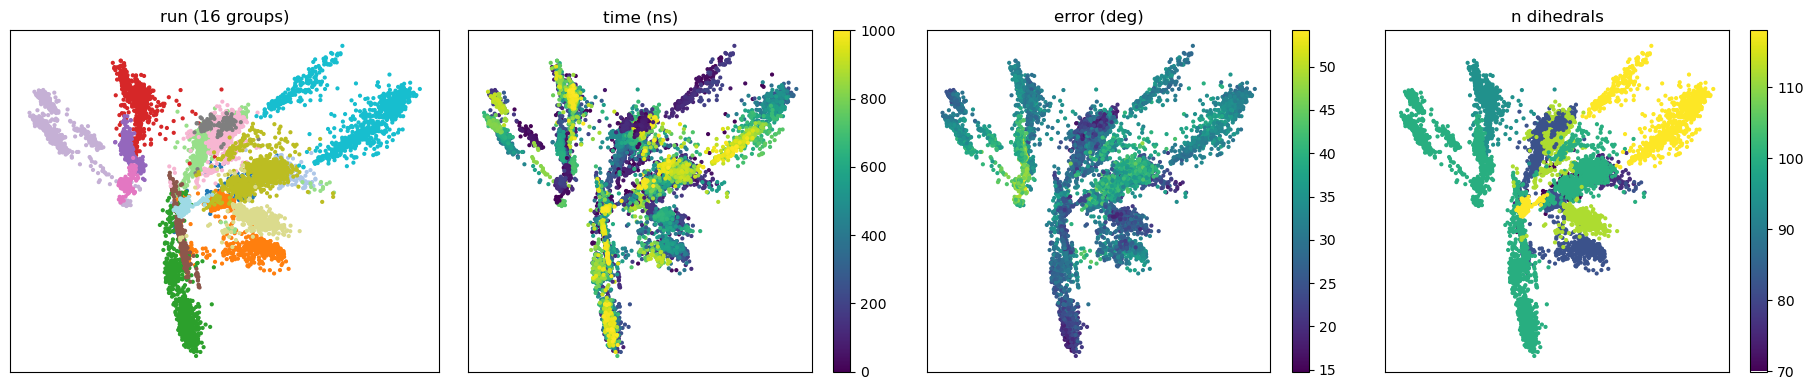

In [16]:
xy, sel = embed_2d(z, "pca")                              # "pca", "tsne" (scikit-learn) or "umap"
scatter_maps(xy, {"run": data["run"][sel], "time (ns)": data["t_ns"][sel],
                  "error (deg)": data["err"][sel], "n dihedrals": data["n_dih"][sel]})   # 2

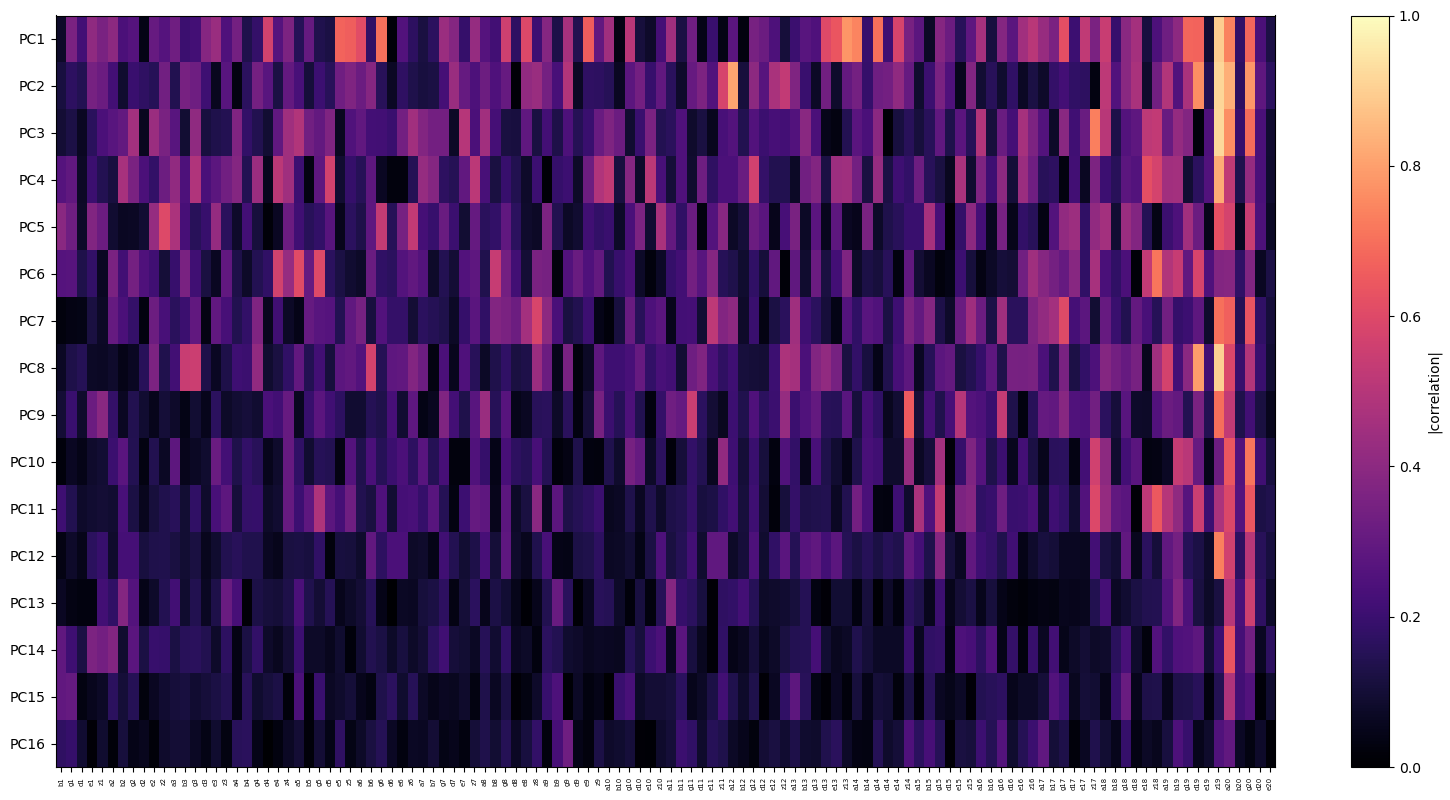

PC1: z19 (0.89), z13 (0.78), a14 (0.74)
PC2: z19 (0.92), a20 (0.84), a12 (0.81)
PC3: z19 (0.92), a20 (0.76), z17 (0.73)
PC4: z19 (0.82), e18 (0.62), z18 (0.58)
PC5: z19 (0.62), z2 (0.60), a20 (0.57)


array([[0.07535476, 0.35704031, 0.21980179, ..., 0.67588593, 0.23629666,
        0.1271289 ],
       [0.1161395 , 0.1703424 , 0.14484991, ..., 0.7837757 , 0.28745831,
        0.16487852],
       [0.09985242, 0.12692213, 0.0659342 , ..., 0.69515533, 0.23510184,
        0.09133224],
       ...,
       [0.29117496, 0.20752581, 0.12463595, ..., 0.33492203, 0.06262357,
        0.16930034],
       [0.29573603, 0.30393447, 0.03316689, ..., 0.25557657, 0.01921897,
        0.08828059],
       [0.17479296, 0.18944213, 0.09351769, ..., 0.03488036, 0.08191241,
        0.01424021]])

In [37]:
latent_dihedral_corr(p["scores"], data["true"], data["valid"], all_names, n_dims=16)                # 3

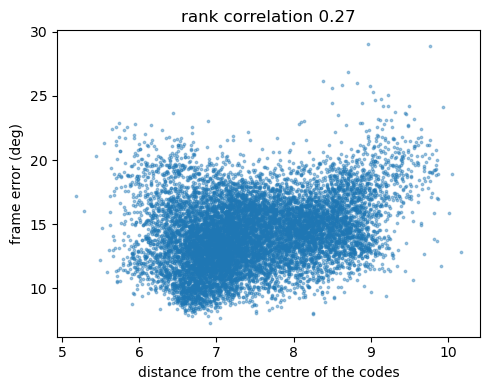

np.float64(0.2738620597146387)

In [33]:
error_vs_distance(z, data["err"])